In [1]:
import numpy as np
import pandas as pd

In [ ]:
'''
stage_1_rank1:
graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'
##################
stage_2_rank1:
graph_path_1 = './result/w_layer/stage2/tuning/bs64_dp0.6_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage2/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage2/df_scaled.csv'
#################
stage_3_rank1:
graph_path_1 = './result/w_layer/stage3/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage3/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage3/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage3/df_scaled.csv'


'''

## stage1

In [2]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

# === 1️⃣ 设定路径 ===
graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

# === 2️⃣ 定义函数：计算平均归一化度中心性 ===
def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  # (T, N, N)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  # 第一列为标签

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    # --- 合并带“-”的子区（取平均） ---
    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name #.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


# === 3️⃣ 分别计算两组结果 ===
mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)


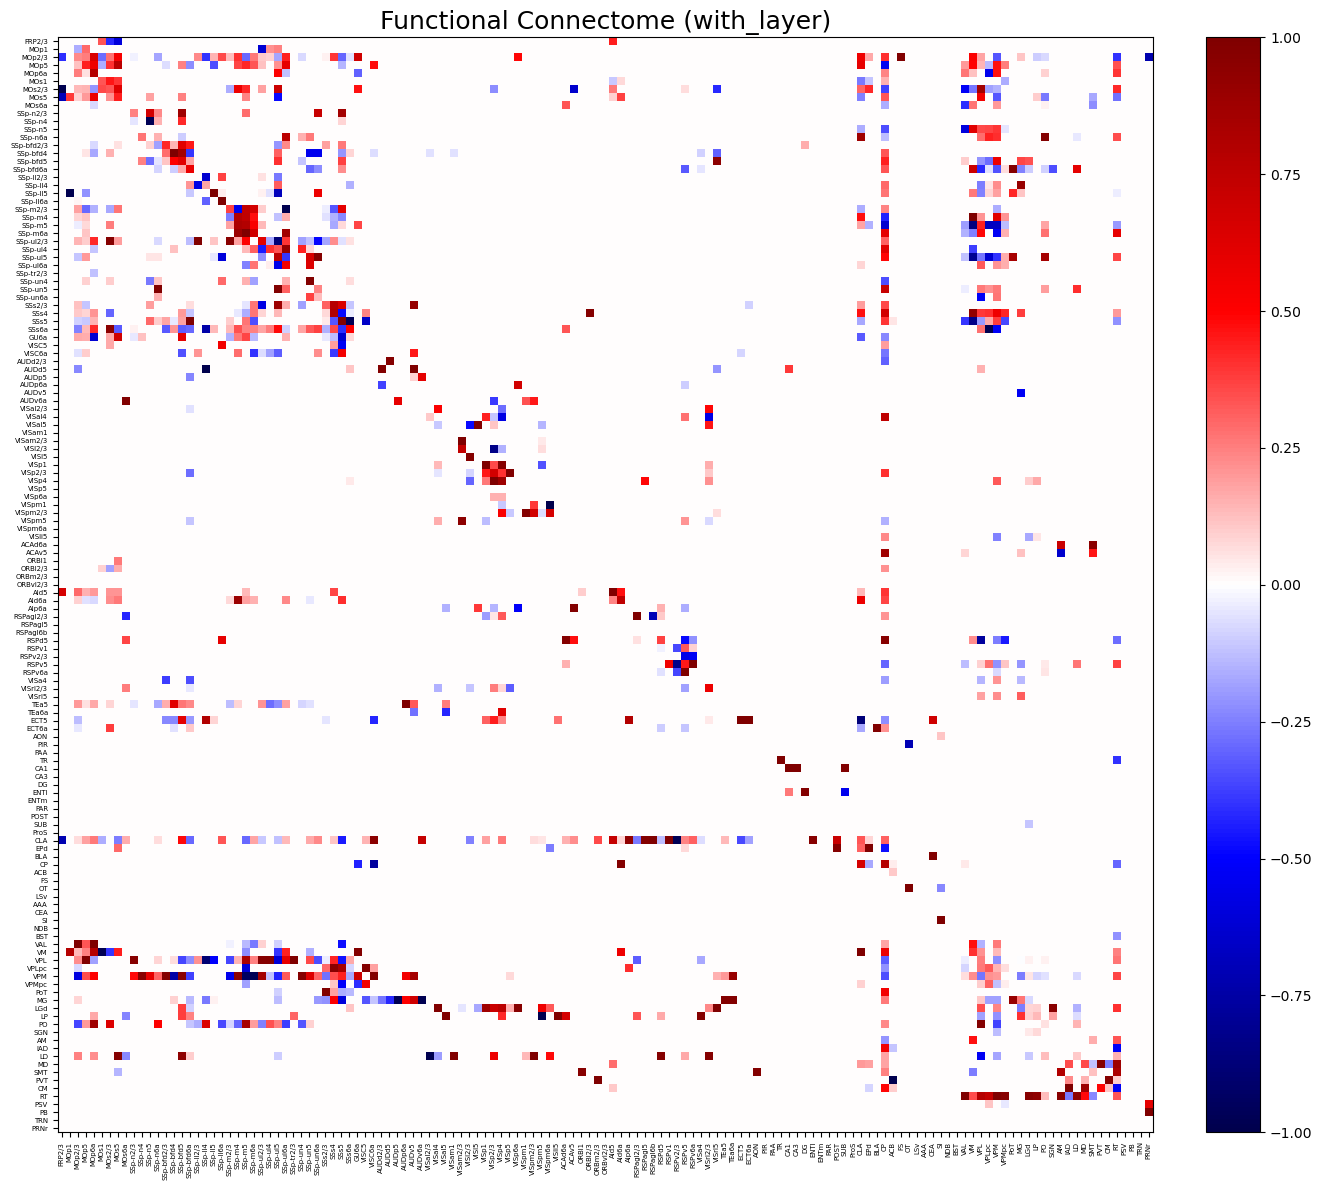

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_1)
df = pd.read_csv(label_path_1)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (with_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=5)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=5)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_w_layer_stage1.jpg", format="jpg", dpi=300)
plt.show()


## stage2

In [5]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

# === 1️⃣ 设定路径 ===
graph_path_1 = './result/w_layer/stage2/tuning/bs64_dp0.6_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage2/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage2/df_scaled.csv'

# === 2️⃣ 定义函数：计算平均归一化度中心性 ===
def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  # (T, N, N)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  # 第一列为标签

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    # --- 合并带“-”的子区（取平均） ---
    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name#.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


# === 3️⃣ 分别计算两组结果 ===
mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)

#print("✅ 组1（含分层）主要脑区中心性：")
#print(mean_dc_1.head())
#print("\n✅ 组2（不含分层）主要脑区中心性：")
#print(mean_dc_2.head())


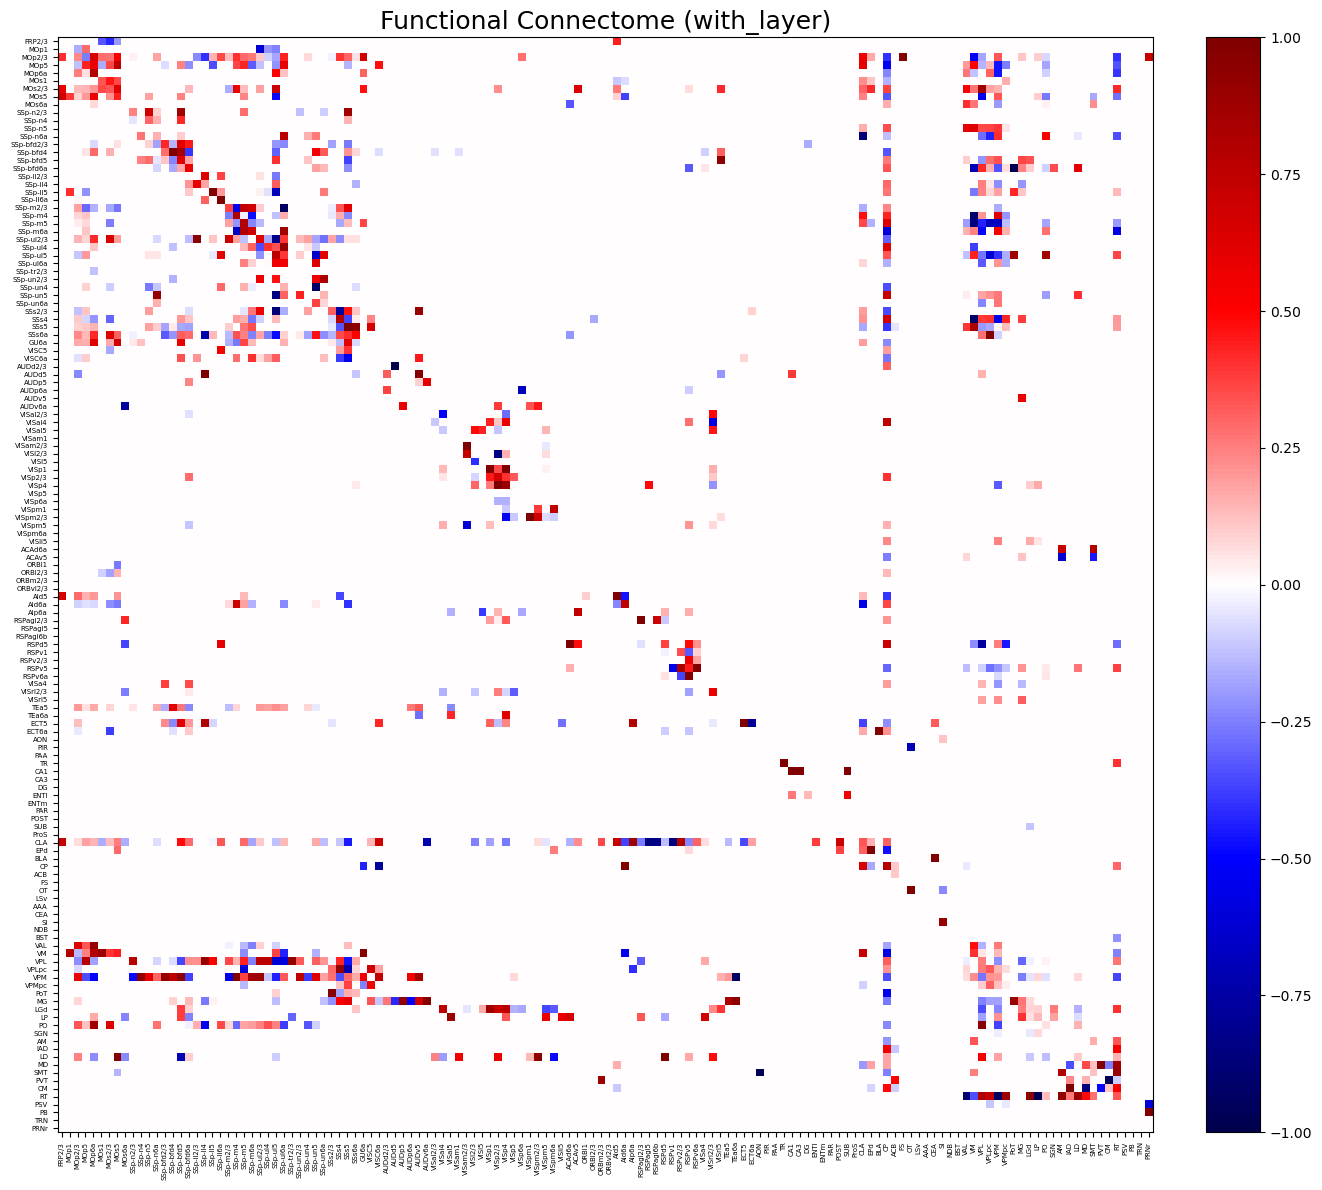

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_1)
df = pd.read_csv(label_path_1)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (with_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=5)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=5)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_w_layer_stage2.jpg", format="jpg", dpi=300)
plt.show()


## stage3

In [7]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

# === 1️⃣ 设定路径 ===
graph_path_1 = './result/w_layer/stage3/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage3/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage3/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage3/df_scaled.csv'

# === 2️⃣ 定义函数：计算平均归一化度中心性 ===
def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  # (T, N, N)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  # 第一列为标签

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    # --- 合并带“-”的子区（取平均） ---
    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name#.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


# === 3️⃣ 分别计算两组结果 ===
mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)


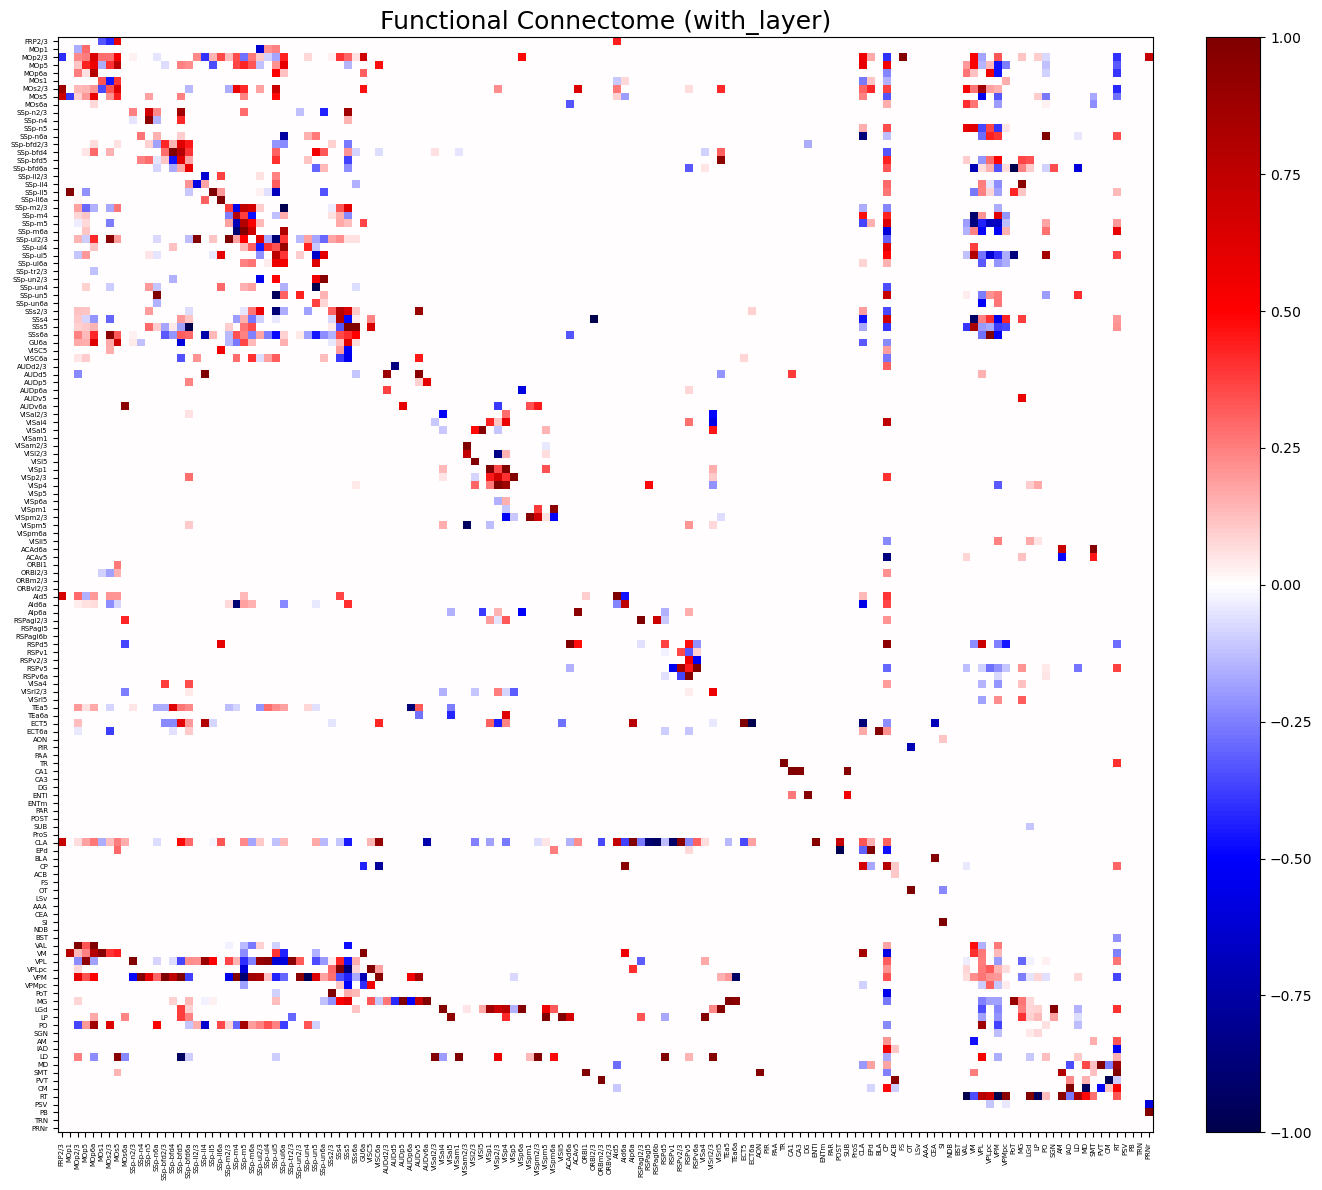

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.family'] = 'DejaVu Sans'
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_1)
df = pd.read_csv(label_path_1)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (with_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=5)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=5)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_w_layer_stage3.jpg", format="jpg", dpi=300)
plt.show()


## Three stages similarity calculation

In [10]:
import numpy as np
import pandas as pd

def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values
    return adj, labels

# paths
stage1_graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
stage1_label_path_1 = './result/w_layer/stage1/df_scaled.csv'

stage2_graph_path_1 = './result/w_layer/stage2/tuning/bs64_dp0.6_sw0.7/dynamic_full_graphs.npy'
stage2_label_path_1 = './result/w_layer/stage2/df_scaled.csv'

stage3_graph_path_1 = './result/w_layer/stage3/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
stage3_label_path_1 = './result/w_layer/stage3/df_scaled.csv'

A1, L1 = load_mean_adj(stage1_graph_path_1, stage1_label_path_1)
A2, L2 = load_mean_adj(stage2_graph_path_1, stage2_label_path_1)
A3, L3 = load_mean_adj(stage3_graph_path_1, stage3_label_path_1)

# find intersection regions
common = sorted(list(set(L1) & set(L2) & set(L3)))

def reorder(adj, labels, common):
    idx = [np.where(labels == c)[0][0] for c in common]
    return adj[np.ix_(idx, idx)]

A1c = reorder(A1, L1, common)
A2c = reorder(A2, L2, common)
A3c = reorder(A3, L3, common)

# --- YOUR CONSISTENCY DEFINITION ---
def consistency(A, B):
    diff = np.abs(A - B)
    triu = np.triu_indices(diff.shape[0], k=1)
    mean_diff = diff[triu].mean()
    return 1 - mean_diff / 2

c12 = consistency(A1c, A2c)
c13 = consistency(A1c, A3c)
c23 = consistency(A2c, A3c)

print("Intersection brain regions:", len(common))
print("Consistency (Stage1 vs Stage2):", round(c12, 4))
print("Consistency (Stage1 vs Stage3):", round(c13, 4))
print("Consistency (Stage2 vs Stage3):", round(c23, 4))


Intersection brain regions: 137
Consistency (Stage1 vs Stage2): 0.99
Consistency (Stage1 vs Stage3): 0.9906
Consistency (Stage2 vs Stage3): 0.9959
